# Student Exam Performance Predictor

**Prepared for the Academic Support Office — Assignment 1**

This notebook explores the supplied student observations, trains a reproducible prediction
prototype, evaluates its errors, and recommends how the results should be used.

Open this notebook in Jupyter Notebook or JupyterLab and select a Python 3 kernel with
NumPy, Pandas, Matplotlib, scikit-learn, and IPython installed. Choose **Restart Kernel and
Run All Cells** to reproduce the complete report. The dataset is embedded below.
The fitted-line visualization appears after model training so every cell runs in order.

## Stage 1 — Define the Problem and Plan the Solution

### A. Project requirements

The Academic Support Office expects the Student Exam Performance Predictor to explore
whether study hours are associated with exam scores in the supplied student dataset.
Its inputs are the provided paired study-hour and exam-score observations, with a study-hour
value supplied separately when requesting a prediction.
The main outputs are numerical summaries, a labeled student table, scatter plots, a fitted
Linear Regression model, and a comparison of predicted and actual held-out scores with MAE.
The final prototype must estimate a score for 7.5 study hours and show why a 100-hour estimate
is unreliable, helping the Office assess a demonstration without claiming that studying
alone causes a particular result.

### B. SDLC plan

| SDLC Stage | Apply it to this project |
|---|---|
| Requirements | Answer the Office's study-hours question using only the supplied observations; report test error, practical predictions, and limits on use. |
| Design | Store paired arrays, calculate statistics, build and inspect a labeled table, explore the scatter, split observations, fit on training data, then evaluate and recommend. |
| Implementation | Use NumPy for numerical storage and statistics, Pandas for inspection and filtering, Matplotlib for both plots, and scikit-learn for splitting, Linear Regression, predictions, and MAE. |
| Testing | Check paired array lengths and finite values, reconcile NumPy and Pandas statistics, confirm disjoint training/test rows, compare held-out predictions with scores, and execute the whole notebook in a fresh kernel. |
| Improvement | Collect a larger, representative student dataset with attendance, prior grades, sleep, and course difficulty; validate on more held-out students before considering operational use. |

### C. Project flow

Office requirements → supplied arrays → numerical profile → DataFrame inspection and filtering
→ exploratory scatter → train/test split → training-only fit → fitted-line plot → test MAE
and practical predictions → limitations and recommendation.

## Stage 2 — Create and Understand the Numerical Dataset

### A. Create the project arrays

Store the supplied pairs once in NumPy arrays. Check that the two arrays have matching
lengths and contain finite values before the Office's analysis begins.

In [1]:
import numpy as np
from IPython.display import Markdown, display

# The supplied raw values are entered only here; later stages reuse these arrays.
study_hours = np.array([1.0, 2.0, 2.5, 3.0, 4.0, 4.5, 5.0, 6.0, 6.5, 7.0, 8.0, 9.0, 10.0])
exam_scores = np.array([42, 48, 51, 55, 62, 65, 69, 75, 78, 82, 87, 91, 95])

assert study_hours.size == exam_scores.size, "Each study-hour value needs an exam score."
assert np.isfinite(study_hours).all() and np.isfinite(exam_scores).all()
print(f"Study-hour observations: {study_hours.size}")
print(f"Exam-score observations: {exam_scores.size}")

Study-hour observations: 13
Exam-score observations: 13


The matching observation counts confirm that every study-hour entry has a corresponding
score. These paired arrays provide one consistent source for the Office's entire prototype.

### B. Produce a short numerical profile

Calculate the profile directly from the arrays. Use the **sample standard deviation**
(`ddof=1`) so its definition agrees with Pandas `describe()` in Stage 3.

In [2]:
observation_count = study_hours.size
mean_study_hours = np.mean(study_hours)
mean_exam_score = np.mean(exam_scores)
minimum_exam_score = np.min(exam_scores)
maximum_exam_score = np.max(exam_scores)
std_exam_score = np.std(exam_scores, ddof=1)
minimum_study_hours = np.min(study_hours)
maximum_study_hours = np.max(study_hours)

print(f"Number of student observations: {observation_count}")
print(f"Average study hours: {mean_study_hours:.2f} hours")
print(f"Average exam score: {mean_exam_score:.2f} points")
print(f"Minimum exam score: {minimum_exam_score:.2f} points")
print(f"Maximum exam score: {maximum_exam_score:.2f} points")
print(f"Sample standard deviation of exam scores: {std_exam_score:.2f} points")
print(f"Observed study-hour range: {minimum_study_hours:g}–{maximum_study_hours:g} hours")

Number of student observations: 13
Average study hours: 5.27 hours
Average exam score: 69.23 points
Minimum exam score: 42.00 points
Maximum exam score: 95.00 points
Sample standard deviation of exam scores: 17.14 points
Observed study-hour range: 1–10 hours


In [3]:
display(Markdown(
    f"The **{observation_count} students** studied for an average of **{mean_study_hours:.2f} hours** "
    f"and achieved an average score of **{mean_exam_score:.2f} points**. "
    f"Scores range from **{minimum_exam_score:g} to {maximum_exam_score:g} points**, "
    f"with a sample standard deviation of **{std_exam_score:.2f} points**, indicating "
    f"noticeable variation around the mean. "
    f"The observed **{minimum_study_hours:g}–{maximum_study_hours:g} hour** range "
    "defines the evidence available for later predictions."
))

The **13 students** studied for an average of **5.27 hours** and achieved an average score of **69.23 points**. Scores range from **42 to 95 points**, with a sample standard deviation of **17.14 points**, indicating noticeable variation around the mean. The observed **1–10 hour** range defines the evidence available for later predictions.

### C. Identify above-average performers

Compare every score with the calculated mean in one vectorized operation, display the
Boolean result in the original observation order, and count its `True` entries.

In [4]:
above_average = exam_scores > mean_exam_score
above_average_count = np.count_nonzero(above_average)

print(f"Above-average flags (original observation order): {above_average}")
print(f"Students scoring above the dataset mean: {above_average_count}")

Above-average flags (original observation order): [False False False False False False False  True  True  True  True  True
  True]
Students scoring above the dataset mean: 6


Each `True` identifies an observation whose exam score exceeds this dataset's mean; `False`
includes scores equal to or below it. The count gives the Office a relative summary of
performance, rather than a university pass threshold.

### D. Explain the operation

For this project, `exam_scores > np.mean(exam_scores)` first calculates the mean of the
supplied exam scores, then compares every student's score with that single threshold.
It returns a Boolean NumPy array of the same length and order as `exam_scores`, allowing
`np.count_nonzero()` to count above-average students without a loop or manual row counting.
Stage 2C reuses the already calculated `mean_exam_score` to perform the same comparison.

The numerical profile shows varied exam performance across a limited range of study hours.
Together with the above-average count, it gives the Academic Support Office a descriptive
baseline; a plot is still needed to inspect the association between hours and scores.

## Stage 3 — Build the Project Data Table and Inspect It

### A. Create the DataFrame

Build the Office's labeled table from the exact arrays created in Stage 2. The observation
index identifies source rows; it is not an additional model feature.

In [5]:
import pandas as pd

df = pd.DataFrame({"StudyHours": study_hours, "ExamScore": exam_scores})
df.index.name = "Observation"
print("Student study-hour and exam-score dataset:")
display(df)

Student study-hour and exam-score dataset:


,StudyHours,ExamScore
Observation,,
0,1.0,42
1,2.0,48
2,2.5,51
3,3.0,55
4,4.0,62
5,4.5,65
6,5.0,69
7,6.0,75
8,6.5,78


The named columns keep each student's hours and score together and make the table easier
for the Office to inspect. No observations have been added or replaced during conversion.

### B. Inspect the dataset

Use `df.head()` to check the first observations and confirm that the column names and
paired values are readable before deriving any new columns.

In [6]:
print("First student observations:")
display(df.head())

First student observations:


,StudyHours,ExamScore
Observation,,
0,1.0,42
1,2.0,48
2,2.5,51
3,3.0,55
4,4.0,62


The preview shows the beginning of the supplied dataset with correctly paired hours and
scores. It checks the table's layout but does not summarize the full range of students.

Read `df.shape` to distinguish the number of student observations from the number of
original variables in the Office's table.

In [7]:
row_count, column_count = df.shape
print(f"DataFrame observations (rows): {row_count}")
print(f"Original DataFrame variables (columns): {column_count}")

DataFrame observations (rows): 13
Original DataFrame variables (columns): 2


The row count matches the paired arrays, and the columns represent study hours and exam
score. This confirms that converting to Pandas preserved the dataset's dimensions.

Use `df.describe()` to inspect counts, means, sample standard deviations, quartiles, and
extremes. Check its main results against the NumPy profile so inconsistent data or
different statistical definitions cannot silently pass into modeling.

In [8]:
dataset_summary = df.describe()
print("Descriptive statistics (StudyHours in hours; ExamScore in points; count in observations):")
display(dataset_summary)

np.testing.assert_allclose(
    dataset_summary.loc["count", ["StudyHours", "ExamScore"]], observation_count
)
np.testing.assert_allclose(
    dataset_summary.loc["mean", ["StudyHours", "ExamScore"]],
    [mean_study_hours, mean_exam_score],
)
np.testing.assert_allclose(
    dataset_summary.loc[["min", "max", "std"], "ExamScore"],
    [minimum_exam_score, maximum_exam_score, std_exam_score],
)
print("NumPy/Pandas consistency checks: passed (both use sample standard deviation).")

Descriptive statistics (StudyHours in hours; ExamScore in points; count in observations):


,StudyHours,ExamScore
count,13.000000,13.000000
mean,5.269231,69.230769
std,2.781002,17.137453
min,1.000000,42.000000
25%,3.000000,55.000000
50%,5.000000,69.000000
75%,7.000000,82.000000
max,10.000000,95.000000


NumPy/Pandas consistency checks: passed (both use sample standard deviation).


The Pandas counts, means, score extremes, and score standard deviation agree with the
NumPy calculations. The quartiles add a view of how hours and scores are distributed,
helping the Office see more than an average alone.

### C. Add a useful project feature

Generate `AboveAverage` from the score column and its mean. This descriptive flag uses
the observed outcome, so it will not be used as an input for predicting that outcome.

In [9]:
df["AboveAverage"] = df["ExamScore"] > df["ExamScore"].mean()
assert np.array_equal(df["AboveAverage"].to_numpy(), above_average)
print("Student table with the calculated AboveAverage flag:")
display(df)

Student table with the calculated AboveAverage flag:


,StudyHours,ExamScore,AboveAverage
Observation,,,
0,1.0,42,False
1,2.0,48,False
2,2.5,51,False
3,3.0,55,False
4,4.0,62,False
5,4.5,65,False
6,5.0,69,False
7,6.0,75,True
8,6.5,78,True


The flag makes above-average observations easy for the Office to identify in the table,
and its values agree with the NumPy comparison. Using this outcome-derived flag as a
predictor would reveal information that is unavailable for a student awaiting an exam.

### D. Answer a stakeholder query

Filter the table for students who studied at least 6 hours **and** scored at least 75 points.
Parenthesize each condition and combine them with `&` so both requirements must hold.

In [10]:
qualifying_students = df[(df["StudyHours"] >= 6) & (df["ExamScore"] >= 75)]
print("Observations meeting both conditions (study hours ≥ 6; exam score ≥ 75 points):")
display(qualifying_students)
print(f"Number of observations meeting both conditions: {len(qualifying_students)}")

Observations meeting both conditions (study hours ≥ 6; exam score ≥ 75 points):


,StudyHours,ExamScore,AboveAverage
Observation,,,
7,6.0,75,True
8,6.5,78,True
9,7.0,82,True
10,8.0,87,True
11,9.0,91,True
12,10.0,95,True


Number of observations meeting both conditions: 6


These rows answer the Office's query directly by keeping only observations meeting both
thresholds. Their high scores are associated with higher study hours in this sample;
the filter does not establish a causal benefit from crossing either threshold.

### E. Explain why Pandas is useful

The NumPy arrays are convenient for calculating the Office's score mean, standard deviation,
and Boolean mask, but the relationship between the two separate arrays depends on matching
positions. The Pandas DataFrame keeps `StudyHours`, `ExamScore`, and `AboveAverage` together
under column names and observation labels, making previews, summaries, and the Office's
two-condition query easier to read and verify. Both representations use the same supplied
observations; Pandas adds structure rather than extra evidence.

## Stage 4 — Explore the Relationship Visually

### A. Create an exploratory scatter plot

Plot the raw observations before fitting a model, with study hours on the horizontal axis
and exam-score points on the vertical axis. A small plotting helper keeps the labels and
scatter style consistent when this visualization is revisited after Stage 5.

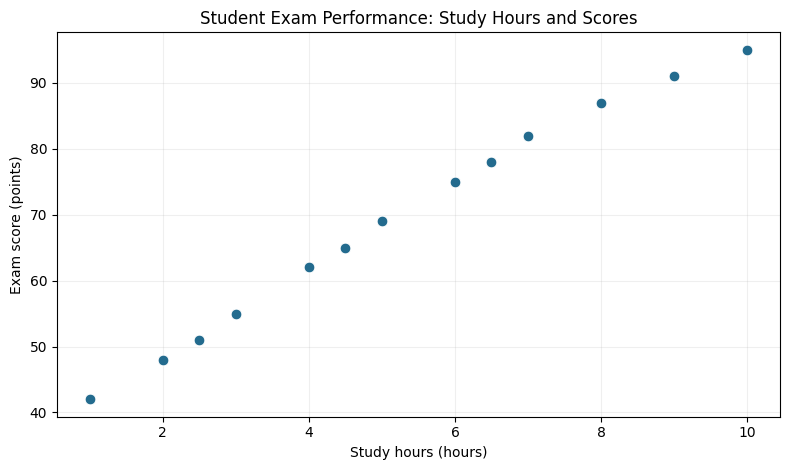

In [11]:
import matplotlib.pyplot as plt


def create_study_score_plot(title):
    '''Create the project's labeled scatter plot for reuse in the fitted-line view.'''
    fig, ax = plt.subplots(figsize=(8, 4.8))
    ax.scatter(
        df["StudyHours"], df["ExamScore"],
        color="#236b8e", s=60, edgecolor="white", linewidth=0.7,
        label="Observed students (all data)", zorder=3,
    )
    ax.set(title=title, xlabel="Study hours (hours)", ylabel="Exam score (points)")
    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)
    fig.tight_layout()
    return fig, ax


fig, ax = create_study_score_plot("Student Exam Performance: Study Hours and Scores")
plt.show()

### B. Write a pre-model observation

The scatter shows a strong positive association: students with more study hours generally
have higher exam scores in the supplied sample. The observations lie close to an upward
trend, with a slight flattening at the highest hours and no obvious isolated unusual point.
This is promising evidence for a simple linear prototype, but the Academic Support Office
cannot infer that extra study hours alone cause the higher scores.

### C. Later add the fitted regression line

The **Stage 4C–D follow-up** immediately after Stage 5 overlays predictions from the trained
model on this scatter. Deferring that code preserves a valid top-to-bottom execution order
and keeps this first view purely exploratory.

### D. Explain the value of the line

For the Academic Support Office, the fitted line turns the observed trend into a consistent
estimated exam score at each study-hour value. Vertical gaps between observations and the
line show where actual performance differs from that estimate; the scatter alone supplies
no fitted prediction rule. A close visual fit still needs held-out evaluation and does not
establish causation.

## Stage 5 — Train the Student Score Prediction Model

### A. Prepare model input and target

Select `StudyHours` as the single input feature and `ExamScore` as the target. Double
brackets keep `X` two-dimensional, as scikit-learn expects, while the target `y` is a Series.

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X = df[["StudyHours"]]
y = df["ExamScore"]

print(f"X shape (observations, input features): {X.shape}")
print(f"y shape (target observations,): {y.shape}")

X shape (observations, input features): (13, 1)
y shape (target observations,): (13,)


The shapes show one study-hour input per student and one score to predict per student.
`AboveAverage` is excluded, so the Office's model only receives information available
before the unknown exam result.

### B. Create training and test sets

Apply the specified split with `test_size=0.2` and `random_state=42`. Check that training
and test rows are disjoint and together account for the full supplied dataset.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

assert X_train.index.intersection(X_test.index).empty
assert len(X_train) + len(X_test) == observation_count
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
print(f"Training observations: {len(X_train)}")
print(f"Test observations: {len(X_test)}")

Training observations: 10
Test observations: 3


The larger subset is used to learn the relationship, while the smaller subset is reserved
for prediction checks on rows unseen during fitting. The fixed random state makes this
comparison reproducible for the Office, although such a small holdout provides limited evidence.

### C. Train the model

Fit Linear Regression using only the training inputs and targets, then label both learned
parameters. The coefficient is measured in exam-score points per study hour.

In [14]:
model = LinearRegression()
model.fit(X_train, y_train)

coefficient = model.coef_[0]
intercept = model.intercept_
print(f"Learned coefficient (exam-score points per study hour): {coefficient:.6f}")
print(f"Learned intercept (exam-score points; mathematical parameter): {intercept:.6f}")
print(f"Prediction equation: ExamScore = {coefficient:.6f} × StudyHours + {intercept:.6f}")

Learned coefficient (exam-score points per study hour): 6.071273
Learned intercept (exam-score points; mathematical parameter): 37.232942
Prediction equation: ExamScore = 6.071273 × StudyHours + 37.232942


In [15]:
display(Markdown(
    f"The coefficient of **{coefficient:.2f} exam-score points per hour** means the fitted "
    "score increases by that amount for each additional study hour. "
    f"The intercept of **{intercept:.2f} points** positions the line at zero study hours, "
    "which is outside the supplied range and should not be treated as a realistic student result. "
    "These parameters describe an association rather than a guaranteed or causal improvement."
))

The coefficient of **6.07 exam-score points per hour** means the fitted score increases by that amount for each additional study hour. The intercept of **37.23 points** positions the line at zero study hours, which is outside the supplied range and should not be treated as a realistic student result. These parameters describe an association rather than a guaranteed or causal improvement.

### D. Generate test predictions

Predict the held-out students' scores and show each prediction alongside its actual score
and study hours. Preserve source-row labels so the comparison can be traced to the original table.

In [16]:
predictions = model.predict(X_test)
test_results = pd.DataFrame({
    "StudyHours": X_test["StudyHours"],
    "ActualExamScore": y_test,
    "PredictedExamScore": predictions,
    "AbsoluteError": np.abs(y_test - predictions),
})
print("Held-out actual versus predicted scores (hours; scores and errors in points):")
display(test_results.round({"PredictedExamScore": 3, "AbsoluteError": 3}))

Held-out actual versus predicted scores (hours; scores and errors in points):


,StudyHours,ActualExamScore,PredictedExamScore,AbsoluteError
Observation,,,,
11,9.0,91,91.874,0.874
9,7.0,82,79.732,2.268
0,1.0,42,43.304,1.304


The predictions are close to the held-out scores, but the differences show that the
line does not reproduce every student exactly. This table gives the Office direct evidence
on unseen rows; Stage 6 summarizes those gaps in exam-score points.

### E. Explain the model pipeline

1. **What is X and what is y in this project?** `X` is the two-dimensional table containing
   only students' study hours; `y` contains their observed exam scores, which the Academic
   Support Office wants the prototype to estimate.
2. **Why do we keep some data for testing?** The Office needs to see whether the learned
   relationship predicts rows excluded from fitting, rather than judging it only on students
   whose scores the model already used; this tiny holdout offers only a preliminary check.
3. **What does model.fit() learn?** From `X_train` and `y_train`, it learns the slope and
   intercept of the line that minimize the sum of squared training-score residuals.
4. **What does model.predict() produce?** For each supplied row of study hours, it returns
   an estimated exam score in points using the learned parameters; those estimates can be
   compared with test scores or requested for a new study-hour scenario.
5. **What does the coefficient mean here?** The printed coefficient is the fitted change
   in predicted exam-score points associated with one additional study hour; it describes
   this sample's model relationship, not a guaranteed gain or a causal effect for an individual.

### Stage 4C–D follow-up — Fitted regression line and interpretation

Now that Stage 5 is complete, revisit the scatter and overlay the training-fitted line.
Generate an ordered grid within the observed hour range and pass its labeled, two-dimensional
table to `model.predict()`; no line values are calculated manually.

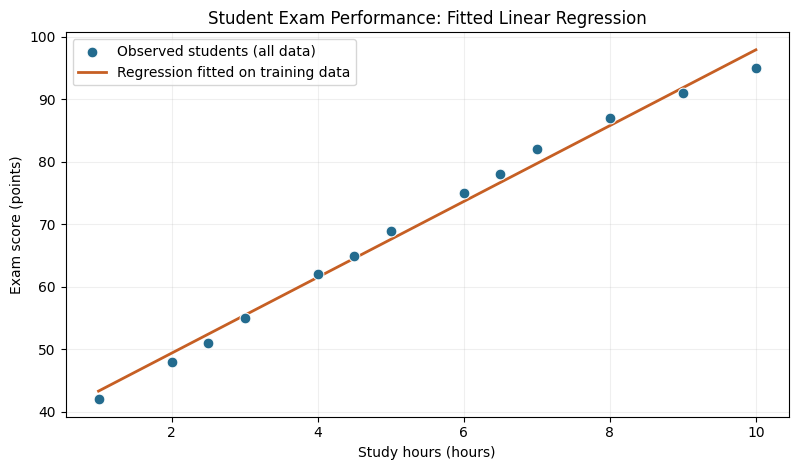

In [17]:
line_inputs = pd.DataFrame({
    "StudyHours": np.linspace(minimum_study_hours, maximum_study_hours, num=200)
})
line_predictions = model.predict(line_inputs)

fig, ax = create_study_score_plot("Student Exam Performance: Fitted Linear Regression")
ax.plot(
    line_inputs["StudyHours"], line_predictions,
    color="#c65f24", linewidth=2, label="Regression fitted on training data",
)
ax.legend(loc="upper left", frameon=True)
plt.show()

The fitted line runs close to the observed points, supporting a reasonable linear summary
for the Office within the observed study-hour range. The slight flattening at the upper end
leaves visible residuals, reminding us that a straight line is an approximation.
Because this scatter includes all observations, the separate test MAE is the held-out check
of prediction error.

## Stage 6 — Evaluate the Prototype and Use It for a Practical Prediction

### A. Evaluate test predictions

Calculate MAE with scikit-learn using the actual held-out scores and the predictions from
Stage 5D. Keep the full-precision predictions for evaluation, regardless of table rounding.

In [18]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, predictions)
print(f"Test mean absolute error (exam-score points): {mae:.6f}")

Test mean absolute error (exam-score points): 1.482254


### B. Interpret MAE

MAE is the mean of the absolute differences between predicted and actual test scores.
Taking absolute values prevents overestimates and underestimates from cancelling out.

In [19]:
display(Markdown(
    f"The test MAE of **{mae:.2f} exam-score points** means predictions were off by "
    f"**{mae:.2f} points on average** across the **{len(y_test)} held-out students**. "
    "This is measured in score points, not a percentage, and is not an error bound for an individual student. "
    "With such a small dataset and test set, this is a demonstration rather than sufficient "
    "evidence for university-wide decisions."
))

The test MAE of **1.48 exam-score points** means predictions were off by **1.48 points on average** across the **3 held-out students**. This is measured in score points, not a percentage, and is not an error bound for an individual student. With such a small dataset and test set, this is a demonstration rather than sufficient evidence for university-wide decisions.

### C. Make a practical prediction

Request the score for 7.5 study hours using a DataFrame with the same feature name as the
training data. Also show the observed range so the Office can see the prediction's context.

In [20]:
practical_study_hours = 7.5
practical_input = pd.DataFrame({"StudyHours": [practical_study_hours]})
practical_prediction = model.predict(practical_input)[0]

print(f"Requested study time: {practical_study_hours:g} hours")
print(f"Predicted exam score: {practical_prediction:.6f} points")
print(f"Observed study-hour range: {minimum_study_hours:g}–{maximum_study_hours:g} hours")

Requested study time: 7.5 hours
Predicted exam score: 82.767492 points
Observed study-hour range: 1–10 hours


This request lies within the observed study-hour range, so it demonstrates interpolation:
the Office can supply a study-hour value between observed values and obtain a fitted estimate.
It remains an approximate exam score, not a promise about an individual student's outcome.

### D. Test the boundary of the prototype

Use the same trained model for the deliberately unrealistic 100-hour scenario. Display the
result without clipping it so the Office can see how far an unsupported extrapolation can go.

In [21]:
extrapolation_study_hours = 100.0
extrapolation_input = pd.DataFrame({"StudyHours": [extrapolation_study_hours]})
extrapolation_prediction = model.predict(extrapolation_input)[0]

print(f"Extrapolation study time: {extrapolation_study_hours:g} hours")
print(f"Extrapolated exam score (unreliable): {extrapolation_prediction:.6f} points")
print(f"Largest observed study time: {maximum_study_hours:g} hours")
print(f"Largest observed exam score: {maximum_exam_score:g} points")

Extrapolation study time: 100 hours
Extrapolated exam score (unreliable): 644.360278 points
Largest observed study time: 10 hours
Largest observed exam score: 95 points


The requested time is far outside the observed range, and the predicted score is far beyond
any score in this dataset. Linear Regression continues its fitted trend without knowing
about realistic score limits or whether the relationship changes at extreme study hours.
The Academic Support Office should not trust this number: producing an output does not make
extrapolation supported by evidence.

## Stage 7 — Write the Final Project Conclusion and Prepare the Submission

### A. Final project conclusion

Present the Office's conclusion below as formatted Markdown. Insert the calculated results
and observation counts from this run so the conclusion stays consistent with the analysis.

In [22]:
conclusion = f"""The Student Exam Performance Predictor gives the Academic Support Office a
reproducible demonstration using the supplied {observation_count} observations. Study hours and
exam scores show a strong positive association, although this does not establish that
additional study alone causes better results. The exploratory scatter is nearly linear,
and the fitted-line plot stays close to the points, with slight flattening at higher hours.
The Linear Regression model therefore appears to fit this small sample reasonably:
its held-out MAE is **{mae:.2f} exam-score points**, the average absolute prediction error
across the {len(y_test)} test students.

For **{practical_study_hours:g} study hours**, the model predicts **{practical_prediction:.2f} points**.
This demonstrates how the Office can obtain an interpolation estimate within the observed
{minimum_study_hours:g}–{maximum_study_hours:g} hour range, not a guaranteed individual result.
The {extrapolation_study_hours:g}-hour output of {extrapolation_prediction:.2f} points illustrates
why extending the line far beyond that range is unreliable.

The prototype has only {observation_count} observations, a single input feature, and a tiny
{len(y_test)}-row test set, so its error estimate may change substantially with different students.
It cannot separate study time from other influences or establish university-wide accuracy.
The Office should collect a larger, representative dataset including attendance, prior grades,
sleep, and course difficulty, then evaluate future models on more unseen students.
For now, this notebook supports exploratory discussion and further data collection,
rather than individual academic decisions."""

conclusion_word_count = len(conclusion.split())
assert 150 <= conclusion_word_count <= 250, "Conclusion must contain 150–250 words."
display(Markdown(conclusion))

The Student Exam Performance Predictor gives the Academic Support Office a
reproducible demonstration using the supplied 13 observations. Study hours and
exam scores show a strong positive association, although this does not establish that
additional study alone causes better results. The exploratory scatter is nearly linear,
and the fitted-line plot stays close to the points, with slight flattening at higher hours.
The Linear Regression model therefore appears to fit this small sample reasonably:
its held-out MAE is **1.48 exam-score points**, the average absolute prediction error
across the 3 test students.

For **7.5 study hours**, the model predicts **82.77 points**.
This demonstrates how the Office can obtain an interpolation estimate within the observed
1–10 hour range, not a guaranteed individual result.
The 100-hour output of 644.36 points illustrates
why extending the line far beyond that range is unreliable.

The prototype has only 13 observations, a single input feature, and a tiny
3-row test set, so its error estimate may change substantially with different students.
It cannot separate study time from other influences or establish university-wide accuracy.
The Office should collect a larger, representative dataset including attendance, prior grades,
sleep, and course difficulty, then evaluate future models on more unseen students.
For now, this notebook supports exploratory discussion and further data collection,
rather than individual academic decisions.

### B. Technical quality

The conclusion supports the Academic Support Office's use of this prototype for exploration
and identifies the extra evidence needed before broader use.

The notebook keeps meaningful variable names, brief comments, labeled results, and one
source for the raw data. Assertions check paired observations, NumPy/Pandas consistency,
matching above-average flags, disjoint train/test rows, and the conclusion's word limit;
the plotting helper avoids repeating the scatter setup. Only training data enter
`model.fit()`, and only held-out targets and predictions enter the MAE calculation.
The delivered notebook includes outputs from a successful fresh-kernel, top-to-bottom execution.

### C. Library understanding

| Library | Role in the Student Performance Predictor |
|---|---|
| NumPy | Store the supplied study hours and scores; calculate the numerical profile, compare scores with their mean, and count above-average students through vectorized operations. |
| Pandas | Represent the same students as a labeled table; inspect `head`, `shape`, and `describe`; create `AboveAverage`; filter the Office's query; and label model inputs and actual/predicted results. |
| Matplotlib | Show the raw study-hours/score association and then overlay the trained model's predicted regression line with clear titles, axes, and a legend. |
| scikit-learn | Create the reproducible train/test split, fit Linear Regression on training students, generate test and scenario predictions, and calculate held-out MAE. |

### Submission Checklist

- [x] I used the provided dataset throughout the entire project.
- [x] My notebook is organized as one continuous Student Exam Performance Predictor project.
- [x] I included all requested code, outputs, plots, and written explanations.
- [x] My scatter plot and regression line are clearly labeled.
- [x] I trained only on the training set and evaluated using the test set.
- [x] I calculated MAE using the test predictions.
- [x] I included the 7.5-hour prediction and explained the 100-hour limitation.
- [x] My final conclusion discusses results, limitations, and future improvements.
- [x] I restarted the kernel and successfully ran the notebook from top to bottom.